# NON LINEAR MODELS STUDY
## Compare model performaces from SVR, GPR, RF and ANN

### 1. Import libraries  

In [1]:
# Imports

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt 
import seaborn as sns
from time import time

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, RandomizedSearchCV, cross_validate
    
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Regression Models
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Persistence
import joblib
import warnings
warnings.filterwarnings('ignore')

# for reproducible plots
#plt.style.use('seaborn-darkgrid')
#plt.style.use('seaborn-whitegrid')


## Load data and select target

In [2]:
# Accessing Data
data_path = Path("~/Documents/PlayTime/LMD_Modelling/data/processed/processed_data.csv").expanduser()
df = pd.read_csv(data_path) 

# target and features
target = 'aspect_ratio'
features = ["Power", "Speed", "Feed"]

X = df[features].copy()
y = df[target].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape) 
print("\nTarget: ", target)
print(y.describe())

# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)       

print("\nTraining set size:", X_train.shape[0])
print("Testing set size:", X_test.shape[0])

Features shape: (89, 3)
Target shape: (89,)

Target:  aspect_ratio
count    89.000000
mean      0.341996
std       0.216554
min       0.077907
25%       0.190595
50%       0.320662
75%       0.402851
max       1.402447
Name: aspect_ratio, dtype: float64

Training set size: 71
Testing set size: 18


## Define Models and Hyperparameter grids

In [8]:
# Cross validation

cv = KFold(n_splits=5, shuffle=True, random_state=42)   

models = {}

# -------SVR ---(RBF Kernel)-----------------
svr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR(kernel='rbf'))
])  

svr_param_grid = {
    'svr__C': [0.1, 1, 10, 100],
    'svr__gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'svr__epsilon': [0.01, 0.1, 0.2, 0.5]
}   

models["SVR"] = {
    'pipeline': svr_pipe,
    'param_grid': svr_param_grid,
    'search_type': 'grid'
}


#-----Gaussian Process Regressor-----------------

kernel = C(1.0, (1e-3, 1e3)) * RBF(length_scale=[1.0, 1.0, 1.0], length_scale_bounds=(1e-2, 1e2)) \
         + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-10, 1e+1))

gpr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('gpr', GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, random_state=42))
])  

gpr_param_grid = {
    'gpr__alpha': [1e-10, 1e-5, 1e-2, 1e-1, 1.0]
}   

models["GPR"] = {
    'pipeline': gpr_pipe,
    'param_grid': gpr_param_grid,
    'search_type': 'grid'
}

#------Random Forest Regressor-----------------
rf_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestRegressor(random_state=42))
])      

rf_param_grid = {
    'rf__n_estimators': [200, 500],
    'rf__max_depth': [None, 5, 10, 15],
    'rf__min_samples_split': [2, 3, 5],
    'rf__min_samples_leaf': [2, 5]
}   
models["RandomForest"] = {
    'pipeline': rf_pipe,
    'param_grid': rf_param_grid,
    'search_type': 'random'
}       

#-------ANNs (MLP Regressor)-----------------
ann_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(max_iter=2000, early_stopping=True, validation_fraction=0.1, random_state=42))
])      

ann_param_grid = {
    'mlp__hidden_layer_sizes': [(20,), (50,), (20, 10), (50, 25)],
    'mlp__activation': ['relu', 'tanh'],
    'mlp__alpha': [0.0001, 0.001, 0.01],
    'mlp__learning_rate_init': [0.001, 0.01, 0.1]
}   
models["ANN"] = {
    'pipeline': ann_pipe,
    'param_grid': ann_param_grid,
    'search_type': 'random'
}   




### Hyperparameter tuning + CV

In [9]:
results = {}

best_models = {}

scoring = {
    "r2": "r2",
    "neg_mean_absolute_error": "neg_mean_absolute_error",
    "neg_mean_squared_error": "neg_mean_squared_error"     
}

for model_name, cfg in models.items():
    print("\n" + "="*60)
    print(f"Training model: {model_name} for target: {target}" )
    print("="*60)   

    start_time = time()  

    if cfg['search_type'] == 'grid':
        search = GridSearchCV(cfg['pipeline'], cfg['param_grid'], cv=cv, n_jobs=-1, scoring= "r2", verbose=1)
    else:
        search = RandomizedSearchCV(cfg['pipeline'], cfg['param_grid'], n_iter=20, cv=cv, n_jobs=-1, scoring= "r2", verbose=1, random_state=42) 
    
    #Fit search on training data

    search.fit(X_train, y_train)

    best_est = search.best_estimator_
    best_models[model_name] = best_est

    # Cross-validate the best estimator
    cv_results = cross_validate(best_est, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=True) 

    # Train/test predictions

    y_train_pred = best_est.predict(X_train)  
    y_test_pred = best_est.predict(X_test)  


    # Training time

    training_time = time() - start_time

    # Results

    results[model_name] = {
        'best_params': search.best_params_,
        'R2_train': r2_score(y_train, y_train_pred),
        'R2_test': r2_score(y_test, y_test_pred),
        'R2_cv_mean': np.mean(cv_results['test_r2']),
        'R2_cv_std': np.std(cv_results['test_r2']),
        'RMSE_train': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'RMSE_test': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'RMSE_cv_mean': np.mean(np.sqrt(-cv_results['test_neg_mean_squared_error'])),
        'RMSE_cv_std': np.std(np.sqrt(-cv_results['test_neg_mean_squared_error'])),
        'MAE_train': mean_absolute_error(y_train, y_train_pred),
        'MAE_test': mean_absolute_error(y_test, y_test_pred),
        'MAE_cv_mean': np.mean(-cv_results['test_neg_mean_absolute_error']),
        'MAE_cv_std': np.std(-cv_results['test_neg_mean_absolute_error']),
        'training_time': training_time
    }   

    print("\nBest Parameters:", search.best_params_)
    print(f"Training time: {training_time:.2f} seconds")
    print(f"R2_CV: {results[model_name]['R2_cv_mean']:.4f} ± {results[model_name]['R2_cv_std']:.4f}")
    print(f"R2_Test: {results[model_name]['R2_test']:.4f}")
    print(f"RMSE_CV: {results[model_name]['RMSE_cv_mean']:.4f} ± {results[model_name]['RMSE_cv_std']:.4f}")
    print(f"MAE_CV: {results[model_name]['MAE_cv_mean']:.4f} ± {results[model_name]['MAE_cv_std']:.4f}")


Training model: SVR for target: aspect_ratio
Fitting 5 folds for each of 80 candidates, totalling 400 fits

Best Parameters: {'svr__C': 100, 'svr__epsilon': 0.01, 'svr__gamma': 0.01}
Training time: 18.60 seconds
R2_CV: 0.9264 ± 0.0299
R2_Test: 0.9652
RMSE_CV: 0.0543 ± 0.0161
MAE_CV: 0.0398 ± 0.0095

Training model: GPR for target: aspect_ratio
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best Parameters: {'gpr__alpha': 1e-05}
Training time: 7.55 seconds
R2_CV: 0.9484 ± 0.0339
R2_Test: 0.9564
RMSE_CV: 0.0419 ± 0.0100
MAE_CV: 0.0309 ± 0.0053

Training model: RandomForest for target: aspect_ratio
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best Parameters: {'rf__n_estimators': 200, 'rf__min_samples_split': 3, 'rf__min_samples_leaf': 2, 'rf__max_depth': 10}
Training time: 20.71 seconds
R2_CV: 0.7835 ± 0.0943
R2_Test: 0.8645
RMSE_CV: 0.0937 ± 0.0391
MAE_CV: 0.0558 ± 0.0129

Training model: ANN for target: aspect_ratio
Fitting 5 folds for each of 20 candid

## Summary of table and best model

In [10]:
# results 

results_df = pd.DataFrame(results).T

summary_cols = ['R2_cv_mean', 'R2_cv_std', 'R2_test',
                'RMSE_cv_mean', 'RMSE_cv_std', 'RMSE_test',
                'MAE_cv_mean', 'MAE_cv_std', 'MAE_test',
                'training_time' ]
summary_df = results_df[summary_cols].round(4).sort_values(by='R2_cv_mean', ascending=False)    

print("\n" + "="*80)  
print(f"Model Performance Summary- TARGET: {target}") 
print("="*80)  
print(summary_df)   

best_models_name = summary_df.index[0]
print("\n" + "="*80)
print(f"Best Model: {best_models_name}")
print("R2_CV:", summary_df.loc[best_models_name, 'R2_cv_mean'])
print("R2_Test:", summary_df.loc[best_models_name, 'R2_test'])
print("RMSE_CV:", summary_df.loc[best_models_name, 'RMSE_cv_mean'])
print("MAE_CV:", summary_df.loc[best_models_name, 'MAE_cv_mean'])
print("="*80)   




Model Performance Summary- TARGET: aspect_ratio
             R2_cv_mean R2_cv_std   R2_test RMSE_cv_mean RMSE_cv_std  \
GPR            0.948352  0.033917  0.956354     0.041858    0.010005   
SVR            0.926382  0.029935   0.96518     0.054313    0.016075   
ANN            0.807322  0.110656  0.842185     0.082453    0.015305   
RandomForest   0.783523  0.094277  0.864517     0.093655     0.03911   

             RMSE_test MAE_cv_mean MAE_cv_std  MAE_test training_time  
GPR           0.031313    0.030866   0.005328  0.026188      7.549058  
SVR           0.027969    0.039757   0.009467  0.022509      18.59565  
ANN           0.059543    0.062427   0.015712  0.042936     12.669322  
RandomForest   0.05517    0.055778   0.012901  0.038881     20.714416  

Best Model: GPR
R2_CV: 0.9483523103457528
R2_Test: 0.956354210473003
RMSE_CV: 0.041857925955920944
MAE_CV: 0.03086598498362349


### Visual Comparisons

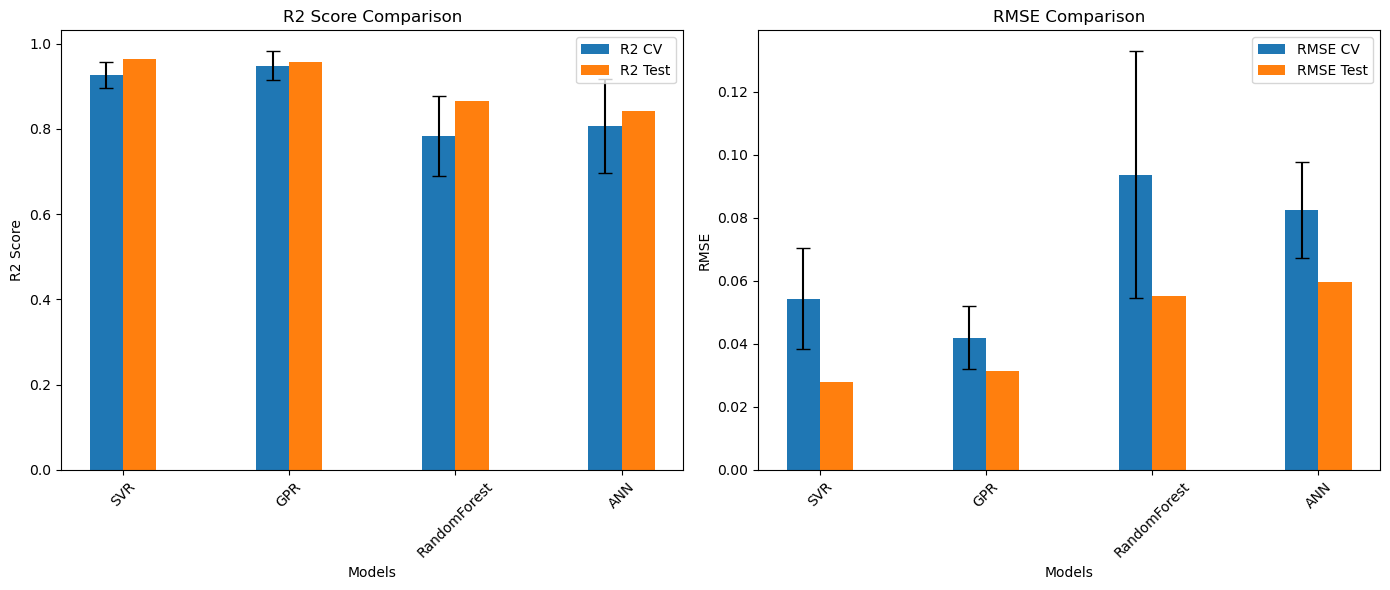

In [11]:
# R2 and RMSE

model_names = list(best_models.keys())
r2_train = [results[model]['R2_train'] for model in model_names]
r2_test = [results[model]['R2_test'] for model in model_names]
rmse_train = [results[model]['RMSE_train'] for model in model_names]
rmse_test = [results[model]['RMSE_test'] for model in model_names]

r2_cv = [results[model]['R2_cv_mean'] for model in model_names]
r2_cv_std = [results[model]['R2_cv_std'] for model in model_names]
rmse_cv = [results[model]['RMSE_cv_mean'] for model in model_names]
rmse_cv_std = [results[model]['RMSE_cv_std'] for model in model_names]

x = np.arange(len(model_names))  # the label locations
width = 0.2  # the width of the bars    


fig, axes = plt.subplots(1, 2, figsize=(14, 6)) 

# R2 Plot
axes[0].bar(x - width/2, r2_cv, width, label='R2 CV', yerr=r2_cv_std, capsize=5)
axes[0].bar(x + width/2, r2_test, width, label='R2 Test')
axes[0].set_xlabel('Models')
axes[0].set_ylabel('R2 Score')
axes[0].set_title('R2 Score Comparison')
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_names, rotation=45)
axes[0].legend()

# RMSE Plot
axes[1].bar(x - width/2, rmse_cv, width, label='RMSE CV', yerr=rmse_cv_std, capsize=5)
axes[1].bar(x + width/2, rmse_test, width, label='RMSE Test')
axes[1].set_xlabel('Models')
axes[1].set_ylabel('RMSE')
axes[1].set_title('RMSE Comparison')
axes[1].set_xticks(x)
axes[1].set_xticklabels(model_names, rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

## Refit best model on full data

In [12]:
# Final Model Training
final_model = best_models[best_models_name] 
final_model.fit(X_train, y_train)

y_full_pred = final_model.predict(X_train)  
r2_full = r2_score(y_train, y_full_pred)
rmse_full = np.sqrt(mean_squared_error(y_train, y_full_pred))   

print("\nFinal Model Performance on Full Training Set:")
print(f"R2 Score: {r2_full:.4f}")
print(f"RMSE: {rmse_full:.4f}") 


# Save the final model and results

results_df.to_csv(f"Nonlinear_models_results{target}.csv")
model_file = f"Best_Nonlinear_Model_{best_models_name}_{target}.pkl"
joblib.dump(final_model, model_file)
print(f"\nFinal model saved to {model_file}") 
print("\nResults saved to ", f"Nonlinear_models_results{target}.csv")
print("saved best model to ", model_file)






Final Model Performance on Full Training Set:
R2 Score: 0.9873
RMSE: 0.0258

Final model saved to Best_Nonlinear_Model_GPR_aspect_ratio.pkl

Results saved to  Nonlinear_models_resultsaspect_ratio.csv
saved best model to  Best_Nonlinear_Model_GPR_aspect_ratio.pkl
